# Deployment bundle: final model + deployed thresholds

This notebook is the **single source of truth** for `coxnet_model_bundle.pkl`: it
fits the final L1-penalised Cox model on the full cohort, derives the three
deployed threshold curves with the **current** rule, and writes everything the
consuming app needs into `deployed_model/`.

The threshold rule here is a verbatim copy of the one measured in
`threshold_2.0_copy.ipynb` (the bootstrap-validation notebook). That notebook
measures the rule; this one ships it. If they ever disagree, this notebook is
wrong.

**What changed from the previous version of this notebook.** All three boundaries
used to come off `fit_dynamic_thresholds` (a ROC-utility argmax for `t_high`, a
bootstrap percentile for `t_low`, both post-processed by a restricted cubic
spline and an empirical-Bayes stage). None of that ships any more:

| boundary | old rule | deployed rule |
|---|---|---|
| `t_high` | ROC-utility argmax + spline + flagged-fraction EB | top-q **cohort**: top 15% by risk at 5 y, membership held from day 0 |
| `t_intermediate` | mean risk, clipped into the two ROC cut-points | mean risk, read straight off the risk matrix |
| `t_low` | 20th-percentile bootstrap curve, clamped by the ROC `t_high` | bottom-q **gap** boundary: whole tie blocks to the 35th percentile, cut placed in the gap above them |

No curve is splined or smoothed on the analysis path.

**Bundle schema is unchanged.** `thresholds_df` still has `time`, `t_low`,
`t_intermediate`, `t_high` and those columns now carry the deployed values, so an
app that compares `risk >= t_high(t)` keeps working. Two things the app should
know about the cohort rule are exported alongside: `high_cohort_cutoff` (the
single number that decides membership) and the day-1..74 tie-break, both
documented in the save cell.

## 1. Inputs

Configuration, imports and the cohort. Nothing here is re-tuned: the model hyperparameters and every threshold setting are fixed inputs copied from the validation notebook.

In [13]:
# =============================================================================
# CONFIG - every tunable quantity in this notebook lives here.
#
# `threshold_params` is a VERBATIM copy of the deployed block in
# threshold_2.0_copy.ipynb. The measurements, the rejected alternatives and the
# reasoning behind every value live in that notebook's CONFIG cell; what is kept
# here is a one-line reminder of what each knob does, so this notebook stays
# readable without duplicating (and eventually contradicting) that write-up.
# =============================================================================
import numpy as np

CONFIG = {
    # ---------------------------------------------------------------- paths --
    "repo_root": "../../../",                       # added to sys.path for `functions.*`
    "data_csv": "../../data/data_cox/data.csv",
    "diagnosis_txt": "../../data/data_cox/diagnosis.txt",
    "treatment_txt": "../../data/data_cox/treatment.txt",

    # ------------------------------------------------- deployment artefacts --
    # The bundle now lives in its OWN folder, together with the deployed
    # threshold table and the run metadata, so the deployed system is one
    # directory rather than a file loose among the analysis outputs.
    "bundle_dir": "deployed_model",
    "bundle_filename": "coxnet_model_bundle.pkl",
    # Backwards compatibility. An identical copy is written here as well, which
    # is the path the consuming app loads today. Set to None once the app points
    # at bundle_dir, and the copy stops being written.
    "legacy_bundle_path": "coxnet_model_bundle.pkl",
    # Before the legacy copy is overwritten, the bundle currently sitting there is
    # renamed to <name>.previous.pkl - one rollback slot, overwritten each run.
    # The app is loading that file today, so a run of this notebook should not be
    # the only thing standing between it and the previous model.
    "keep_previous_legacy_bundle": True,
    "save_bundle": True,

    # ------------------------------------------------------ cohort building --
    "event_col": "Regional LN recurrence",
    "time_col": "Survival days",
    # Administrative cap: follow-up beyond this day is censored at this day.
    "administrative_cap_days": 1826.0,
    "continuous_features": [
        "Age",
        "Ki67 positive cells (%) at CB",
        "Conventional RT fraction",
        "Total administered dose",
        "Boost dose administered",
    ],

    # ------------------------------------------- FIXED model (do NOT re-tune) --
    # Final chosen L1-penalised Cox hyperparameters.
    "model_params": {
        "alphas": [0.000621017],
        "l1_ratio": 1.0,
        "fit_baseline_model": True,
    },

    # ----------------------------------------------------------- time grids --
    # The derivation grid is daily and covers the full 5-year window; the rule is
    # defined on it, so it is not coarsened here.
    "times": np.arange(1, 1826, dtype=float),
    "reporting_horizons": [365.0, 1095.0, 1825.0],   # 1 y, 3 y, 5 y (days)
    "primary_horizon": 1825.0,

    # -------------------------------------------------- SurvSHAP background --
    # Reproducible train subsample stored in the bundle as reference data.
    # Unchanged from the previous bundle: same size, same seed, same draw.
    "shap_reference_size": 200,
    "shap_reference_seed": 42,

    # ------------------------------------------------------------ zone rule --
    "zone_labels": ["zone_1_low", "zone_2_mid_low", "zone_3_mid_high", "zone_4_high"],
    # 0.0 = no day is masked out of the flag accumulation. Under the cohort high
    # rule the flagged share is q on every day including day 1, so there is no
    # early ramp left to mask.
    "flag_accumulation_start_time": 0.0,
    # Inert under a cohort high rule (the per-day comparison against c_high(t) is
    # never made). Read only if high_rule is switched back to "roc_utility".
    "flag_comparison": ">=",
    "ci_alpha": 0.05,                   # -> 2.5th / 97.5th percentiles

    # --------------------------------------------------------- legacy table --
    # True  : run fit_dynamic_thresholds as well, so the bundle carries the legacy
    #         ROC-utility/EB columns (event_prevalence, m_value_high, roc_n_used,
    #         ...) as diagnostics, exactly as the validation notebook does. Costs
    #         a few minutes; NONE of the deployed curves depend on it.
    # False : skip it. The three deployed curves are byte-identical either way -
    #         c_low, c_medium and c_high are all pure functions of the risk matrix
    #         - and the run takes seconds. The legacy diagnostic columns are then
    #         absent from thresholds_df.
    "compute_legacy_table": True,
    # The full (n_patients x n_days) risk matrix is stored in the bundle as
    # threshold_result.risk_scores_train, as it was before. It is ~47 MB of the
    # ~48 MB pickle. Set False for a small bundle if the app does not read it.
    "store_risk_matrix": True,

    # ----------------------------------------------------------- figures ----
    "save_coefficient_figures": True,

    # -------------------------------------- pass-through to derive_thresholds --
    "threshold_params": {
        # ---------------------------------------------- HIGH-ZONE DERIVATION --
        # DEPLOYED: rank the fitting sample by predicted risk at
        # reference_horizon, take the top q, and hold that membership from day 0.
        # FB(t) = q at every horizon by construction and no resample can run away.
        #
        # It replaces the ROC-utility argmax, which is unidentified at this event
        # count: with the model frozen and only the labels resampled, c_high(5y)
        # still moved over 9.8x and c_high(1y) over 236x, 3% of draws landing on
        # the degenerate "flag nobody" vertex. q is set to the FLAG BURDEN TARGET
        # itself (FB <= 0.15 is a declared design criterion), not tuned against
        # event capture. Measured out-of-bag at 5 y: FB median 0.156, EC median
        # 0.700, against EC 0.500 for the argmax at the same burden.
        "high_rule": {
            "method": "top_q_cohort",       # or "top_q_curve" / "roc_utility"
            "q": 0.15,
            "reference_horizon": 1825.0,
        },
        # ----------------------------------------------- LOW-ZONE DERIVATION --
        # DEPLOYED: take whole tie blocks up to the target percentile and place
        # the boundary in the GAP above them, at the geometric midpoint of the two
        # bracketing risk trajectories.
        #
        # Every one of the 9 non-zero coefficients sits on a binary feature, so
        # predicted risk takes only 213 distinct values over 3228 patients and the
        # bottom of the distribution is a few very large tie blocks. A plain
        # percentile lands ON a block (np.percentile(risk, 20) matched the next
        # block to within 1.6e-13), so a refit decides several hundred memberships
        # by floating-point noise. 35.0 selects the 38.01% block boundary, whose
        # gap is 12.18% of the risk value; the out-of-bag low-zone IQR falls from
        # 14.2 to 4.6 percentage points and the 25/497 empty low zones go to 0.
        "low_rule": {
            "method": "bottom_q_gap",       # or "legacy_percentile"
            "percentile": 35.0,             # -> the 38.01% block boundary
            "reference_horizon": 1825.0,
        },
        # --- everything below is handed to fit_dynamic_thresholds unchanged ----
        "n_bootstrap": 50,                  # inner bootstrap of the legacy low curve
        "low_percentile": 35.0,             # legacy t_low column (diagnostic only)
        "low_threshold_method": "bootstrap_percentile",
        "intermediate_threshold_method": "mean_risk",
        "high_threshold_method": "roc_utility",
        # No curve is splined any more: on the tail replicates the spline
        # undershot to ~0.001 across days 900-1500 and the EB stage transmitted
        # that through the prior it draws from exactly those horizons, flagging
        # the whole cohort.
        "curve_spline_postprocess": "none",
        "curve_spline_variant": "restricted",
        "curve_spline_quantiles": (0.10, 0.50, 0.90),
        "curve_spline_knots_within_grid": True,
        # OFF. A centred rolling mean displaced c_low across tie blocks (a
        # constant 492 patients became 0-1309 over the grid) while cutting the
        # across-replicate sd of c_low by under 1%.
        "low_medium_smoothing": {"enabled": False, "window_days": 121},
        # MUST be None while curve_spline_postprocess is "none".
        "high_curve_min_knot_time": None,
        # DISABLED. None is the off value here; 0.0 would switch the pin ON.
        "high_curve_zero_start_time": None,
        "high_curve_terminal_extrapolation": "flat",
        "high_eb_shrink_k": 3.0,
        "eb_support_counts": "cumulative_events",
        # Flagged-fraction EB. Still runs inside fit_dynamic_thresholds, but under
        # a top-q high rule its curve is DISCARDED and never exported.
        "high_percentile_eb": True,
        "high_percentile_eb_k": 10.0,
        "high_percentile_eb_min_events": 10,
        "high_percentile_eb_monotone": True,
        "high_percentile_eb_prior": "median",
        "high_false_positive_cost": 1.0,
        "high_false_negative_cost": 80,
        "high_true_positive_cost": 0.0,
        "high_true_negative_cost": 0.0,
        "stratified_bootstrap": True,
        "max_time_bins_for_bootstrap_strata": 3,
        "prevalence_method": "kaplan_meier",
        # None = per-horizon m (standard dynamic-ROC practice). Affects only the
        # legacy columns now.
        "prevalence_reference_time": None,
        "utility_weighting": "ipcw",
        "threshold_estimation_method": "point",
        "random_state": 12,                 # held fixed: part of the fixed procedure
        "verbose": False,
    },
}

print("CONFIG loaded.")
print(f"  bundle      : {CONFIG['bundle_dir']}/{CONFIG['bundle_filename']}")
print(f"  legacy copy : {CONFIG['legacy_bundle_path']}")
print(f"  high rule   : {CONFIG['threshold_params']['high_rule']}")
print(f"  low rule    : {CONFIG['threshold_params']['low_rule']}")
print(f"  medium rule : {CONFIG['threshold_params']['intermediate_threshold_method']}")

CONFIG loaded.
  bundle      : deployed_model/coxnet_model_bundle.pkl
  legacy copy : coxnet_model_bundle.pkl
  high rule   : {'method': 'top_q_cohort', 'q': 0.15, 'reference_horizon': 1825.0}
  low rule    : {'method': 'bottom_q_gap', 'percentile': 35.0, 'reference_horizon': 1825.0}
  medium rule : mean_risk


In [14]:
# ---- Imports, paths and library versions ------------------------------------
import os
import sys
import json
import time
import pickle
import shutil
import platform
from datetime import datetime

REPO_ROOT = os.path.abspath(CONFIG["repo_root"])
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import sksurv
import scipy
from sklearn.base import BaseEstimator
from sklearn.preprocessing import MinMaxScaler
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.metrics import concordance_index_censored, concordance_index_ipcw

import functions.threshold as threshold_module

BUNDLE_DIR = os.path.abspath(CONFIG["bundle_dir"])
os.makedirs(BUNDLE_DIR, exist_ok=True)
BUNDLE_PATH = os.path.join(BUNDLE_DIR, CONFIG["bundle_filename"])
LEGACY_BUNDLE_PATH = (
    None if CONFIG["legacy_bundle_path"] is None
    else os.path.abspath(CONFIG["legacy_bundle_path"])
)

LIB_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
    "scikit-survival": sksurv.__version__,
    "matplotlib": matplotlib.__version__,
}

print("run started :", datetime.now().isoformat(timespec="seconds"))
print("bundle dir  :", BUNDLE_DIR)
print("bundle path :", BUNDLE_PATH)
print("legacy copy :", LEGACY_BUNDLE_PATH)
print("library versions:")
for _k, _v in LIB_VERSIONS.items():
    print(f"  {_k:<16s} {_v}")

run started : 2026-09-01T19:57:42
bundle dir  : c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model
bundle path : c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\coxnet_model_bundle.pkl
legacy copy : c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\coxnet_model_bundle.pkl
library versions:
  python           3.11.13
  numpy            2.3.1
  pandas           2.3.2
  scipy            1.16.2
  scikit-learn     1.7.2
  scikit-survival  0.25.0
  matplotlib       3.10.6


In [15]:
# ---- Cohort, design matrix and survival array -------------------------------
# Identical preparation to threshold_2.0_copy.ipynb: same column order
# (treatment + diagnosis), same administrative cap, same min-max scaling of the
# continuous columns fitted once on the full cohort. The variable NAMES kept here
# (x_train_scaled, y_train, scaler) are the ones the bundle ships under.
_raw = pd.read_csv(CONFIG["data_csv"])
survival_dataset = _raw.drop(columns=[c for c in ["Unnamed: 0"] if c in _raw.columns])

with open(CONFIG["diagnosis_txt"], "r") as _f:
    diagnosis_variables = [line.strip() for line in _f if line.strip()]
with open(CONFIG["treatment_txt"], "r") as _f:
    treatment_variables = [line.strip() for line in _f if line.strip()]
feature_columns = treatment_variables + diagnosis_variables
continuous_features = list(CONFIG["continuous_features"])

_missing = [c for c in feature_columns if c not in survival_dataset.columns]
if _missing:
    raise KeyError(f"Feature columns absent from the data file: {_missing}")

# Administrative censoring at the cap.
_cap = float(CONFIG["administrative_cap_days"])
_beyond = survival_dataset[CONFIG["time_col"]] > _cap
survival_dataset.loc[_beyond, CONFIG["event_col"]] = 0
survival_dataset.loc[_beyond, CONFIG["time_col"]] = _cap

data_x = survival_dataset[feature_columns]
y_train = Surv.from_arrays(
    event=survival_dataset[CONFIG["event_col"]],
    time=survival_dataset[CONFIG["time_col"]],
)

scaler = MinMaxScaler()
x_train_scaled = data_x.copy()
_cols_to_scale = [c for c in continuous_features if c in x_train_scaled.columns]
x_train_scaled[_cols_to_scale] = scaler.fit_transform(x_train_scaled[_cols_to_scale])
x_train_scaled = x_train_scaled.reset_index(drop=True)

EVENT = y_train[y_train.dtype.names[0]].astype(bool)
TIME = y_train[y_train.dtype.names[1]].astype(float)
N_PATIENTS = int(x_train_scaled.shape[0])

TIMES = np.asarray(CONFIG["times"], dtype=float)
time_points = TIMES                                     # bundle-facing alias
report_time_points = np.asarray(CONFIG["reporting_horizons"], dtype=float)
TIME_TO_IDX = {float(t): i for i, t in enumerate(TIMES)}
for _h in list(CONFIG["reporting_horizons"]) + [CONFIG["primary_horizon"]]:
    if float(_h) not in TIME_TO_IDX:
        raise ValueError(f"Reporting horizon {_h} is not on CONFIG['times'].")
HORIZON_IDX = {float(h): TIME_TO_IDX[float(h)] for h in CONFIG["reporting_horizons"]}

print(f"rows (patients)   : {N_PATIENTS}")
print(f"events            : {int(EVENT.sum())}")
print(f"censored          : {int((~EVENT).sum())}")
print(f"follow-up (days)  : {TIME.min():.0f} - {TIME.max():.0f}")
print(f"features          : {x_train_scaled.shape[1]}  (scaled: {len(_cols_to_scale)})")
print(f"missing cells in X: {int(x_train_scaled.isna().sum().sum())}")
print(f"derivation grid   : {TIMES.size} days ({TIMES[0]:.0f}-{TIMES[-1]:.0f})")

rows (patients)   : 3228
events            : 27
censored          : 3201
follow-up (days)  : 25 - 1826
features          : 29  (scaled: 5)
missing cells in X: 0
derivation grid   : 1825 days (1-1825)


## 2. The deployed derivation rule

The rule itself, copied from `threshold_2.0_copy.ipynb`, plus the metric definitions used to check the result. `functions/threshold.py` is imported, never edited.

In [16]:
# ---- The deployed derivation rule -------------------------------------------
# Copied from threshold_2.0_copy.ipynb (section "the fixed model and the existing
# derivation rule"). The CODE is identical, so the curves this notebook ships are
# the curves that notebook validated; the docstrings are trimmed to what a reader
# of the DEPLOYED system needs, and point back there for the measurements.
#
# The derivation logic in functions/threshold.py is not reimplemented and not
# edited. `derive_thresholds` hands `fit_dynamic_thresholds` a stand-in estimator
# that replays a precomputed risk matrix, so the legacy diagnostic table comes out
# of the same code path as before, while the three curves that actually ship are
# computed here from the risk matrix directly.


def MODEL_FACTORY():
    """Return an UNFITTED L1-penalised Cox model with the final hyperparameters."""
    return CoxnetSurvivalAnalysis(**CONFIG["model_params"])


def _threshold_module():
    """Import functions.threshold, re-adding the repo root if it went missing."""
    import sys as _sys
    if REPO_ROOT not in _sys.path:
        _sys.path.insert(0, REPO_ROOT)
    from functions import threshold as _t
    return _t


def predict_risk_trajectory(model, X_data, times):
    """(n_patients, n_times) predicted risk, on the cumulative-incidence
    convention the thresholds use: risk = 1 - S(t)."""
    return _threshold_module()._build_risk_matrix(model, X_data, times)


class _StepFunctionFromRisk:
    """Minimal StepFunction stand-in that replays one patient's risk trajectory."""

    __slots__ = ("x", "_survival")

    def __init__(self, x, survival):
        self.x = x
        self._survival = survival

    def __call__(self, t):
        return np.interp(np.asarray(t, dtype=float), self.x, self._survival)


class _PrecomputedRiskModel(BaseEstimator):
    """Estimator stand-in returning a fixed risk matrix, so the existing
    `fit_dynamic_thresholds` can be driven from an already-computed risk matrix
    without altering a single line of its derivation logic.

    NOTE: instances of this class are never put in the bundle. The bundle ships
    the real fitted CoxnetSurvivalAnalysis, so unpickling it does not depend on
    this notebook's classes being importable.
    """

    def __init__(self, risk_matrix=None, times=None):
        self.risk_matrix = risk_matrix
        self.times = times

    def fit(self, X, y=None):
        return self

    def predict_survival_function(self, X):
        grid = np.asarray(self.times, dtype=float)
        survival = 1.0 - np.asarray(self.risk_matrix, dtype=float)
        return [_StepFunctionFromRisk(grid, survival[i]) for i in range(survival.shape[0])]


def _rolling_mean_smooth(curve, window_days):
    """Centred rolling mean, bounded by its own window's min/max at every point.

    INACTIVE on the deployed path: low_medium_smoothing is off. Kept so that arm
    can be switched back on for comparison. Edges shrink the window on BOTH sides
    rather than extrapolating, which keeps the average centred; clipping only the
    overhanging side biased the endpoint towards the interior and collapsed the
    low zone at day 1825.
    """
    curve = np.asarray(curve, dtype=float)
    window_days = int(window_days)
    if window_days < 1 or window_days % 2 == 0:
        raise ValueError("window_days must be a positive odd integer.")
    if window_days == 1 or curve.size < 3:
        return curve.copy()
    half = window_days // 2
    finite = np.isfinite(curve)
    filled = np.where(finite, curve, 0.0)
    cum = np.concatenate([[0.0], np.cumsum(filled)])
    cnt = np.concatenate([[0.0], np.cumsum(finite.astype(float))])
    idx = np.arange(curve.size)
    half_eff = np.minimum(half, np.minimum(idx, curve.size - 1 - idx))
    lo = idx - half_eff
    hi = idx + half_eff + 1
    n_used = cnt[hi] - cnt[lo]
    out = np.divide(cum[hi] - cum[lo], n_used,
                    out=np.full(curve.shape, np.nan), where=n_used > 0)
    return np.where(finite, out, curve)


def _bootstrap_percentile_curve(risk_matrix, y_fit, percentile, n_bootstrap,
                                stratified, max_time_bins, random_state):
    """The RAW low-risk curve: pointwise median, over inner stratified bootstrap
    resamples, of the `percentile`-th percentile of predicted risk.

    INACTIVE on the deployed path (low_rule is "bottom_q_gap"); kept for the
    legacy_percentile arm. It is recomputed here rather than read off the returned
    table because `fit_dynamic_thresholds` closes every horizon with
    t_low = min(low_raw, high_raw), so its t_low column is min(percentile, the
    discarded ROC c_high) -- the last route by which that argmax could reach the
    deployed system.
    """
    tm = _threshold_module()
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    events = np.asarray(tm._extract_event_indicator(y_fit), dtype=bool)
    times_obs = np.asarray(tm._extract_time_values(y_fit), dtype=float)

    rng = np.random.default_rng(random_state)
    if stratified:
        strata = tm._build_bootstrap_strata_labels(
            events=events, times=times_obs, max_time_bins=int(max_time_bins),
        )
        index_sets = [tm._stratified_bootstrap_indices(rng, strata)
                      for _ in range(int(n_bootstrap))]
    else:
        n = int(risk_matrix.shape[0])
        index_sets = [rng.choice(n, size=n, replace=True)
                      for _ in range(int(n_bootstrap))]

    boot = np.vstack([
        np.percentile(risk_matrix[idx, :], float(percentile), axis=0)
        for idx in index_sets
    ])
    return np.clip(np.median(boot, axis=0), 0.0, 1.0)


def _bottom_q_gap_boundary(risk_matrix, times, percentile, reference_horizon):
    """THE DEPLOYED LOW BOUNDARY, placed in a GAP of the predicted-risk lattice.

    Returns (boundary_curve, in_low_mask, report).

      1. rank the fitting sample by predicted risk at `reference_horizon`;
      2. read the `percentile` cut-point and drop back to the last DISTINCT risk
         level at or below it, so the low group is a union of whole tie blocks and
         no block is ever split;
      3. return, at every horizon, the geometric midpoint between the highest
         trajectory inside that group and the lowest trajectory outside it.

    Step 3 is what buys the stability: the boundary sits in the middle of a gap in
    the risk lattice rather than on one of its rungs, so the group only changes
    when a refit moves a patient across half a gap, not across a rounding error.
    At the deployed setting that gap is 12.18% of the risk value; the block the
    old percentile rule sat on had 0.99% above it.

    The geometric rather than arithmetic mean is used because predicted risk is
    1 - S0(t)^exp(eta): the curves are multiplicatively spaced, and the geometric
    midpoint is the arithmetic midpoint on the log-risk scale, where the model is
    linear.

    Like _top_q_boundary this is a RANK rule, so it is invariant to any monotone
    transformation of the risk scale and the selected group is the same at every
    horizon on which the model separates anyone at all. Where the Breslow baseline
    has not yet stepped every predicted risk is identically zero, no ranking
    exists, and the curve is returned as zero for those days; classify() reads a
    boundary of exactly zero as "everybody is in the lowest zone".
    """
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    times = np.asarray(times, dtype=float)
    ref_idx = int(np.argmin(np.abs(times - float(reference_horizon))))
    ref_col = risk_matrix[:, ref_idx]
    n = int(ref_col.shape[0])
    empty = (np.zeros(times.size, dtype=float), np.zeros(n, dtype=bool), None)

    levels = np.unique(ref_col)
    if levels.size < 2:
        # No spread at the reference horizon: no boundary separates anybody.
        return empty

    cut = float(np.percentile(ref_col, float(percentile)))
    # searchsorted "right" lands one past the last level <= cut, so k-1 indexes the
    # highest level inside the low group. k == 0 means the percentile fell below
    # the smallest risk in the sample, i.e. the low group is empty.
    k = int(np.searchsorted(levels, cut, side="right"))
    if k <= 0:
        return empty
    if k >= levels.size:
        # The percentile reached the top of the lattice; keep the highest block out
        # so the group is a proper subset and a boundary still exists.
        k = levels.size - 1
    in_low = ref_col <= levels[k - 1]

    inside_max = risk_matrix[in_low].max(axis=0)
    outside_min = risk_matrix[~in_low].min(axis=0)
    live = (inside_max > 0.0) & (outside_min > 0.0)
    curve = np.where(live, np.sqrt(inside_max * outside_min), 0.0)

    report = {
        "percentile": float(percentile),
        "reference_idx": ref_idx,
        "cutoff": float(curve[ref_idx]),
        "percentile_value": cut,
        "n_low": int(in_low.sum()),
        "share_low": float(in_low.mean()),
        "level_below": float(levels[k - 1]),
        "level_above": float(levels[k]),
        # Relative width of the gap the boundary sits in, at the reference
        # horizon. This is the quantity that makes the rule stable; it is asserted
        # to be non-zero below rather than assumed.
        "gap_relative": float((levels[k] - levels[k - 1]) / levels[k - 1])
        if levels[k - 1] > 0.0 else float("nan"),
        "n_levels": int(levels.size),
        # False would mean the two bracketing trajectories cross somewhere on the
        # grid, i.e. the risk ordering is not preserved across horizons and the
        # selected group is not time-invariant after all.
        "ordered_on_grid": bool(np.all(inside_max[live] <= outside_min[live])),
    }
    return curve, in_low, report


def _top_q_boundary(risk_matrix, times, q, reference_horizon):
    '''The patient sitting exactly on the top-q boundary of the fitting sample.

    Returns (cutoff, boundary_curve). `cutoff` is that patient's risk at
    reference_horizon; `boundary_curve` is their whole trajectory. Because a Cox
    risk is monotone in the linear predictor at every horizon, "risk above this
    patient's curve" and "in the top q by risk at the reference horizon" are the
    same set of patients on every day the model can separate anyone at all --
    which is why the curve form is exact from day 75 onwards (the first observed
    event, the first day any patient has non-zero risk) and undefined before it.
    '''
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    times = np.asarray(times, dtype=float)
    ref_idx = int(np.argmin(np.abs(times - float(reference_horizon))))
    ref_col = risk_matrix[:, ref_idx]
    n = ref_col.shape[0]
    # CEIL, not floor. Membership is "risk >= c*" and c* is the value AT rank k, so
    # the boundary patient is inside the cohort and the flagged count is n - k.
    # With k = floor((1 - q) n) that count is n - floor(0.85 n) >= 0.15 n for EVERY
    # n, i.e. the design criterion is missed by construction before a single tie is
    # considered (485/3228 = 15.03%). ceil gives n - ceil(0.85 n) <= 0.15 n instead
    # (484 = 14.99%). Ties at the cutoff can still carry the realised share over q;
    # that is counted and reported, not assumed away.
    k = int(np.clip(np.ceil((1.0 - float(q)) * n), 0, n - 1))
    boundary_row = int(np.argsort(ref_col, kind="mergesort")[k])
    return float(ref_col[boundary_row]), risk_matrix[boundary_row, :].copy()


def high_cohort_mask(risk_matrix, thresholds):
    '''Bool per patient: is this patient in the fixed high-risk cohort?

    None when the deployed rule is not cohort-based, in which case every consumer
    falls back to the ordinary "risk above c_high(t)" comparison.
    '''
    cutoff = thresholds.get("high_cohort_cutoff")
    if cutoff is None:
        return None
    ref_idx = int(thresholds["high_reference_idx"])
    return np.asarray(risk_matrix, dtype=float)[:, ref_idx] >= float(cutoff)


def derive_thresholds(risk_matrix, y_fit, times, compute_legacy_table=True,
                      **threshold_params):
    """The deployed threshold-derivation rule, as a pure function.

    risk_matrix : (n_fit_patients, n_times) predicted risk for the fitting sample.
    Returns {"c_low", "c_medium", "c_high"} (each length n_times) plus diagnostics
    and, when compute_legacy_table is True, the legacy table.

    All three deployed curves are pure functions of the risk matrix:
      c_low    : _bottom_q_gap_boundary
      c_medium : the cohort mean predicted risk
      c_high   : _top_q_boundary
    Nothing that ships comes off the ROC utility, the spline or the EB stages any
    more. `compute_legacy_table=False` therefore leaves every deployed curve
    byte-identical and only drops the diagnostic columns.

    No curve is smoothed: curve_spline_postprocess is "none" and
    low_medium_smoothing is off. The ordering c_low <= c_medium <= c_high is
    applied here in either case.
    """
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    times = np.asarray(times, dtype=float)
    # low_medium_smoothing, high_rule and low_rule are private to this wrapper:
    # fit_dynamic_thresholds has no such parameters. Popping them out of a COPY of
    # threshold_params keeps this a pure function of its arguments and keeps the
    # call below passing only parameters that function accepts.
    threshold_params = dict(threshold_params)
    lm_cfg = threshold_params.pop("low_medium_smoothing", {"enabled": False, "window_days": 1})
    hr_cfg = threshold_params.pop(
        "high_rule", {"method": "roc_utility", "q": 0.15, "reference_horizon": 1825.0}
    )
    lr_cfg = threshold_params.pop(
        "low_rule", {"method": "legacy_percentile", "percentile": 20.0,
                     "reference_horizon": 1825.0}
    )
    _int_method = str(threshold_params.get("intermediate_threshold_method", "youden_j")).strip().lower()
    _low_method = str(threshold_params.get("low_threshold_method", "roc_utility")).strip().lower()

    if compute_legacy_table:
        stand_in = _PrecomputedRiskModel(risk_matrix=risk_matrix, times=times)
        placeholder_x = pd.DataFrame(index=np.arange(risk_matrix.shape[0]))
        result = _threshold_module().fit_dynamic_thresholds(
            estimator=stand_in,
            x_train=placeholder_x,
            y_train=y_fit,
            time_points=times,
            **threshold_params,
        )
        table = result.thresholds
        c_low = table["t_low"].to_numpy(dtype=float)
        c_medium = table["t_intermediate"].to_numpy(dtype=float)
        c_high = table["t_high"].to_numpy(dtype=float)
    else:
        # Skipping the legacy table is only admissible when NO deployed curve would
        # have been read off it. Under the deployed configuration none is; a
        # configuration that switches an arm back to the legacy behaviour must run
        # the table, so this raises rather than silently shipping zeros.
        _needs_table = (
            hr_cfg["method"] == "roc_utility"
            or _int_method not in ("mean_risk", "mean")
            or (lr_cfg["method"] == "legacy_percentile" and _low_method != "bootstrap_percentile")
        )
        if _needs_table:
            raise ValueError(
                "compute_legacy_table=False, but this configuration reads a deployed "
                "curve off fit_dynamic_thresholds (high_rule=%r, "
                "intermediate_threshold_method=%r, low_rule=%r/%r). Set it to True."
                % (hr_cfg["method"], _int_method, lr_cfg["method"], _low_method)
            )
        result = None
        table = None
        c_low = np.zeros(times.size, dtype=float)
        c_medium = np.zeros(times.size, dtype=float)
        c_high = np.zeros(times.size, dtype=float)

    # ---- medium boundary ----------------------------------------------------
    # c_medium is the cohort's MEAN predicted risk, read straight off the risk
    # matrix rather than out of the table. fit_dynamic_thresholds clips its
    # t_intermediate into [min, max] of the two ROC cut-points; with
    # high_false_negative_cost = 80 the slope m(t) falls below 1 on days
    # 1784-1825, where the utility is maximised by flagging everybody and the
    # cut-point collapses, and the clip then dragged the mean down with it
    # (0.013157 -> 0.010575 at day 1825, the primary horizon).
    if _int_method in ("mean_risk", "mean"):
        c_medium = risk_matrix.mean(axis=0)

    # ---- low boundary -------------------------------------------------------
    c_low_table = c_low.copy()
    low_cohort_mask_arr = None
    low_gap_report = None
    if lr_cfg["method"] == "bottom_q_gap":
        # The deployed rule. No inner bootstrap: it was measured to have the same
        # out-of-bag spread as the plain percentile to the first decimal, and a
        # median of percentiles cannot move a cutoff off a tie block in any case.
        c_low, low_cohort_mask_arr, low_gap_report = _bottom_q_gap_boundary(
            risk_matrix, times,
            percentile=lr_cfg["percentile"],
            reference_horizon=lr_cfg["reference_horizon"],
        )
    elif lr_cfg["method"] == "legacy_percentile":
        if _low_method == "bootstrap_percentile":
            c_low = _bootstrap_percentile_curve(
                risk_matrix=risk_matrix,
                y_fit=y_fit,
                percentile=threshold_params.get("low_percentile", 1.0),
                n_bootstrap=threshold_params.get("n_bootstrap", 200),
                stratified=bool(threshold_params.get("stratified_bootstrap", False)),
                max_time_bins=threshold_params.get("max_time_bins_for_bootstrap_strata", 5),
                random_state=threshold_params.get("random_state", 12),
            )
    else:
        raise ValueError("unknown low_rule method %r" % (lr_cfg["method"],))
    c_low_raw = c_low.copy()

    # ---- high-zone rule -----------------------------------------------------
    high_cohort_cutoff = None
    high_reference_idx = int(np.argmin(np.abs(times - float(hr_cfg["reference_horizon"]))))
    if hr_cfg["method"] in ("top_q_cohort", "top_q_curve"):
        _cut, _boundary = _top_q_boundary(
            risk_matrix, times, hr_cfg["q"], hr_cfg["reference_horizon"]
        )
        c_high = _boundary
        if hr_cfg["method"] == "top_q_cohort":
            high_cohort_cutoff = _cut
    elif hr_cfg["method"] != "roc_utility":
        raise ValueError("unknown high_rule method %r" % (hr_cfg["method"],))

    if lm_cfg["enabled"]:
        c_low = _rolling_mean_smooth(c_low, lm_cfg["window_days"])
        c_medium = _rolling_mean_smooth(c_medium, lm_cfg["window_days"])

    # The ordering is re-imposed UNCONDITIONALLY. fit_dynamic_thresholds enforces
    # it on ITS OWN curves, and all three deployed curves are computed here
    # instead, so nothing upstream has ordered the curves that actually ship.
    #
    # c_high is held FIXED rather than sorted with the other two: under a top-q
    # rule it is the decision boundary of a cohort chosen at the reference
    # horizon, and letting a sort swap it for c_medium would silently redefine who
    # is in that cohort. c_low and c_medium are ordered between themselves and
    # then capped at c_high.
    _lo = np.minimum(c_low, c_medium)
    _mid = np.maximum(c_low, c_medium)
    c_low = np.minimum(_lo, c_high)
    c_medium = np.minimum(_mid, c_high)

    return {
        "c_low": c_low,
        "c_medium": c_medium,
        "c_high": c_high,
        # Diagnostics for the low boundary: the curve as fit_dynamic_thresholds
        # returned it (its own percentile, clamped by the ROC c_high) and the
        # deployed curve that replaced it. Both PRE-smoothing.
        "c_low_table": c_low_table,
        "c_low_raw": c_low_raw,
        # None unless the deployed low rule is the gap rule. When set, it is the
        # boolean membership of the low zone decided at the reference horizon, and
        # low_gap_report carries the placement diagnostics.
        "low_cohort_mask": low_cohort_mask_arr,
        "low_gap_report": low_gap_report,
        # None unless the deployed high rule is cohort-based. When set, membership
        # of the top zone is "risk at the reference horizon >= this", decided once
        # and active from day 0 -- not a per-day comparison against c_high(t).
        "high_cohort_cutoff": high_cohort_cutoff,
        "high_reference_idx": high_reference_idx,
        "times": times,
        "table": table,
        # The raw DynamicThresholdResult, for diagnostics only. It is NOT what
        # goes in the bundle: its fitted_model is the stand-in above.
        "result": result,
    }


def classify(risk_matrix, thresholds):
    """(n_patients, n_times) integer zone labels, 0 = lowest zone.

    The three curves are sorted per time point, then r < c_low -> 0,
    r < c_medium -> 1, r < c_high -> 2, else 3.
    """
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    stacked = np.vstack([
        np.asarray(thresholds["c_low"], dtype=float),
        np.asarray(thresholds["c_medium"], dtype=float),
        np.asarray(thresholds["c_high"], dtype=float),
    ])
    ordered = np.sort(stacked, axis=0)          # (3, n_times)
    zones = np.zeros(risk_matrix.shape, dtype=np.int8)
    for k in range(ordered.shape[0]):
        boundary = ordered[k][None, :]
        # A boundary of exactly zero is not a boundary. Before the first observed
        # event day (day 75 here) the Breslow baseline has not stepped, so every
        # predicted risk is identically zero -- and so are all three curves. ">= 0"
        # is then true for everybody against all three, which sweeps the entire
        # cohort into the HIGHEST band. Nobody has accrued any risk over that
        # stretch, so the defensible reading of the tie is the LOWEST zone: a
        # patient counts as above a zero boundary only once their own risk is
        # strictly positive. Where the boundary is positive this is the ordinary
        # ">=" rule, unchanged.
        #
        # Nothing at 1, 3 or 5 y moves. What this fixes is the DEPLOYED artefact:
        # applying the exported table at day 60 used to label 85% of the cohort
        # "medium-high" purely because the baseline had not stepped yet.
        zones += (
            (risk_matrix >= boundary) & ((boundary > 0.0) | (risk_matrix > 0.0))
        ).astype(np.int8)

    # Under a cohort rule the top zone is a membership decided once at the
    # reference horizon and held from day 0, so it replaces the per-day comparison
    # against c_high. The two lower boundaries are untouched.
    cohort = high_cohort_mask(risk_matrix, thresholds)
    if cohort is not None:
        zones = np.minimum(zones, 2).astype(np.int8)
        zones[cohort, :] = 3
    return zones


print("MODEL_FACTORY    :", MODEL_FACTORY())
print("threshold params :", len(CONFIG["threshold_params"]), "pass-through keys")

MODEL_FACTORY    : CoxnetSurvivalAnalysis(alphas=[0.000621017], fit_baseline_model=True,
                       l1_ratio=1.0)
threshold params : 34 pass-through keys


In [17]:
# ---- Metric primitives (same definitions as the validation notebook) --------
# Used here only to CHECK the bundle: flag burden must come out at exactly q, and
# the zone occupancy / incidence table must match what was validated.

def flag_matrix(risk_matrix, c_high, times, start_time, comparison, cohort=None):
    """(n, n_times) bool: is this patient flagged at this time point?"""
    risk_matrix = np.asarray(risk_matrix, dtype=float)
    # Cohort rule: membership was decided once at the reference horizon and holds
    # from day 0, so the per-day comparison against c_high(t) is bypassed
    # entirely. This is not expressible as a threshold curve -- before day 75 the
    # model gives every patient a risk of exactly zero, so no line separates
    # anyone -- which is why it is a separate branch rather than a c_high value.
    if cohort is not None:
        cohort = np.asarray(cohort, dtype=bool)
        flagged = np.repeat(cohort[:, None], np.size(times), axis=1)
        flagged[:, np.asarray(times, dtype=float) < float(start_time)] = False
        return flagged
    c_high = np.asarray(c_high, dtype=float)[None, :]
    if comparison == ">=":
        flagged = risk_matrix >= c_high
    elif comparison == ">":
        flagged = risk_matrix > c_high
    else:
        raise ValueError("CONFIG['flag_comparison'] must be '>' or '>='.")
    flagged[:, np.asarray(times, dtype=float) < float(start_time)] = False
    return flagged


def first_flag_days(risk_matrix, c_high, times, start_time, comparison, cohort=None):
    """Per patient: the first day they are flagged, or NaN if never."""
    times = np.asarray(times, dtype=float)
    flagged = flag_matrix(risk_matrix, c_high, times, start_time, comparison, cohort)
    ever_any = flagged.any(axis=1)
    first_idx = np.argmax(flagged, axis=1)
    out = np.full(flagged.shape[0], np.nan, dtype=float)
    out[ever_any] = times[first_idx[ever_any]]
    return out


def _ever_flagged_by(first_flag, query_times):
    ff = np.where(np.isnan(first_flag), np.inf, first_flag)
    return ff[:, None] <= np.asarray(query_times, dtype=float)[None, :]


def flag_burden_curve(first_flag, query_times):
    """FB(t): share of ALL patients ever flagged by t. No censoring adjustment."""
    n = int(np.size(first_flag))
    if n == 0:
        return np.full(np.size(query_times), np.nan)
    return _ever_flagged_by(first_flag, query_times).mean(axis=0)


def event_capture_curve(first_flag, event, time, query_times):
    """EC(t): among patients who recurred by t, the share ever flagged at or
    before their own event time. Returns (curve, numerator, denominator)."""
    query_times = np.asarray(query_times, dtype=float)
    ff = np.where(np.isnan(first_flag), np.inf, first_flag)
    captured = ff <= np.asarray(time, dtype=float)
    recurred_by = np.asarray(event, dtype=bool)[:, None] & (
        np.asarray(time, dtype=float)[:, None] <= query_times[None, :]
    )
    denominator = recurred_by.sum(axis=0).astype(float)
    numerator = (recurred_by & captured[:, None]).sum(axis=0).astype(float)
    curve = np.divide(
        numerator, denominator,
        out=np.full(query_times.shape, np.nan, dtype=float),
        where=denominator > 0,
    )
    return curve, numerator, denominator


def km_curve(time_v, event_v):
    """Kaplan-Meier. Returns (event_times, survival, at_risk, greenwood_cum)."""
    time_v = np.asarray(time_v, dtype=float)
    event_v = np.asarray(event_v, dtype=bool)
    if time_v.size == 0:
        empty = np.empty(0, dtype=float)
        return empty, empty, empty, empty
    distinct = np.unique(time_v[event_v])
    if distinct.size == 0:
        return np.empty(0), np.empty(0), np.empty(0), np.empty(0)
    at_risk = np.array([(time_v >= t).sum() for t in distinct], dtype=float)
    deaths = np.array([(event_v & (time_v == t)).sum() for t in distinct], dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        factors = np.where(at_risk > 0, 1.0 - deaths / at_risk, 0.0)
    survival = np.cumprod(np.clip(factors, 0.0, 1.0))
    denominator = at_risk * (at_risk - deaths)
    increments = np.divide(deaths, denominator,
                           out=np.zeros_like(deaths), where=denominator > 0)
    return distinct, survival, at_risk, np.cumsum(increments)


def km_cif_at(time_v, event_v, horizon, alpha=0.05):
    """Cumulative incidence 1 - S(horizon) with a log-log (Greenwood) interval."""
    from scipy.stats import norm

    time_v = np.asarray(time_v, dtype=float)
    if time_v.size == 0:
        return np.nan, np.nan, np.nan
    distinct, survival, at_risk, greenwood = km_curve(time_v, event_v)
    if distinct.size == 0:
        return 0.0, 0.0, 0.0
    reached = distinct <= float(horizon)
    if not np.any(reached):
        return 0.0, 0.0, 0.0
    j = int(np.max(np.flatnonzero(reached)))
    s_hat = float(survival[j])
    if s_hat <= 0.0 or s_hat >= 1.0:
        return float(1.0 - s_hat), np.nan, np.nan
    log_s = np.log(s_hat)
    sigma = float(np.sqrt(greenwood[j]) / abs(log_s))
    z = float(norm.ppf(1.0 - float(alpha) / 2.0))
    lower_s = s_hat ** np.exp(z * sigma)
    upper_s = s_hat ** np.exp(-z * sigma)
    return float(1.0 - s_hat), float(1.0 - upper_s), float(1.0 - lower_s)


def zone_summary(zones_at_horizon, event, time, horizon, alpha):
    """Zone occupancy and outcome at one horizon."""
    labels = CONFIG["zone_labels"]
    zones_at_horizon = np.asarray(zones_at_horizon, dtype=int)
    event = np.asarray(event, dtype=bool)
    time = np.asarray(time, dtype=float)
    total = int(zones_at_horizon.size)

    rows = []
    for z, label in enumerate(labels):
        mask = zones_at_horizon == z
        n = int(mask.sum())
        if n == 0:
            rows.append({"horizon": float(horizon), "zone": z, "zone_label": label,
                         "n": 0, "pct": np.nan, "observed_events": 0,
                         "cif": np.nan, "cif_lo": np.nan, "cif_hi": np.nan})
            continue
        events_by_h = int((mask & event & (time <= float(horizon))).sum())
        cif, lo, hi = km_cif_at(time[mask], event[mask], horizon, alpha)
        rows.append({"horizon": float(horizon), "zone": z, "zone_label": label,
                     "n": n, "pct": n / total, "observed_events": events_by_h,
                     "cif": cif, "cif_lo": lo, "cif_hi": hi})
    return pd.DataFrame(rows)


print("metric primitives ready")

metric primitives ready


## 3. Fit and derive

One fit on the full cohort, one derivation. This is the apparent (full-data) run the validation notebook reports as its reference, so the curves below must match its `deployed_thresholds.csv` exactly.

In [18]:
# ---- Fit the final model and derive the deployed thresholds -----------------
# One fit on the full cohort, one derivation. This is the apparent (full-data)
# run: the same one threshold_2.0_copy.ipynb reports as its apparent reference,
# so the curves below must match that notebook's deployed_thresholds.csv exactly.
_t0 = time.perf_counter()

# Bundle-facing alias for the fixed hyperparameters, kept under its old name.
best_params_for_calibration = dict(CONFIG["model_params"])
intermediate_threshold_method = CONFIG["threshold_params"]["intermediate_threshold_method"]

cox_model = MODEL_FACTORY().fit(x_train_scaled, y_train)
# The bundle has always shipped `fitted_threshold_model` alongside `cox_model`.
# They used to be two separate fits of the same estimator on the same data (the
# second one made inside fit_dynamic_thresholds); the derivation now runs off a
# precomputed risk matrix, so there is one fit and the two names are the same
# object. Both keys are kept so the app does not have to change.
fitted_threshold_model = cox_model

RISK = predict_risk_trajectory(cox_model, x_train_scaled, TIMES)
THRESHOLDS = derive_thresholds(
    RISK, y_train, TIMES,
    compute_legacy_table=CONFIG["compute_legacy_table"],
    **CONFIG["threshold_params"],
)
threshold_result_raw = THRESHOLDS["result"]     # legacy object, diagnostics only

ZONES = classify(RISK, THRESHOLDS)
COHORT = high_cohort_mask(RISK, THRESHOLDS)
LOW_COHORT = THRESHOLDS["low_cohort_mask"]

print(f"derivation took {time.perf_counter() - _t0:.1f} s "
      f"(legacy table: {CONFIG['compute_legacy_table']})")

# ---- Sanity checks on the derived boundaries -------------------------------
_gap = THRESHOLDS["low_gap_report"]
if _gap is None:
    raise RuntimeError("The low boundary did not come from the gap rule - check low_rule.")
if not _gap["ordered_on_grid"]:
    raise AssertionError(
        "The two trajectories bracketing the low boundary cross somewhere on the "
        "grid, so the low group is not time-invariant. Do not ship this bundle."
    )
if not (_gap["gap_relative"] > 0.0):
    raise AssertionError("The low boundary was placed on a tie block, not in a gap.")

if THRESHOLDS["high_cohort_cutoff"] is None:
    raise RuntimeError("The high boundary did not come from the cohort rule - check high_rule.")
_q_target = float(CONFIG["threshold_params"]["high_rule"]["q"])
_flagged_share = float(COHORT.mean())
_ties_at_cut = int((RISK[:, THRESHOLDS["high_reference_idx"]] == THRESHOLDS["high_cohort_cutoff"]).sum())

_ordered = np.all(THRESHOLDS["c_low"] <= THRESHOLDS["c_medium"] + 1e-15) and np.all(
    THRESHOLDS["c_medium"] <= THRESHOLDS["c_high"] + 1e-15)
if not _ordered:
    raise AssertionError("c_low <= c_medium <= c_high does not hold on every day.")

print("\nlow boundary (gap rule):")
print(f"  percentile asked        : {_gap['percentile']:.1f}")
print(f"  block boundary selected : {_gap['share_low'] * 100:.2f}% of the cohort "
      f"({_gap['n_low']} patients)")
print(f"  cutoff at {CONFIG['threshold_params']['low_rule']['reference_horizon']:.0f} d : "
      f"{_gap['cutoff']:.8f}")
print(f"  gap it sits in          : {_gap['gap_relative'] * 100:.2f}% of the risk value "
      f"({_gap['level_below']:.8f} -> {_gap['level_above']:.8f})")
print(f"  distinct risk levels    : {_gap['n_levels']} over {N_PATIENTS} patients")

print("\nhigh boundary (top-q cohort rule):")
print(f"  q target                : {_q_target:.4f}")
print(f"  cohort cutoff           : {THRESHOLDS['high_cohort_cutoff']:.8f} "
      f"(risk at {CONFIG['threshold_params']['high_rule']['reference_horizon']:.0f} d)")
print(f"  realised flagged share  : {_flagged_share:.4f} "
      f"({int(COHORT.sum())} patients)"
      + ("  <- ties carried it over q" if _flagged_share > _q_target else ""))
print(f"  patients tied at cutoff : {_ties_at_cut}")

# ---- Apparent operating characteristics ------------------------------------
FIRST_FLAG = first_flag_days(
    RISK, THRESHOLDS["c_high"], TIMES,
    CONFIG["flag_accumulation_start_time"], CONFIG["flag_comparison"], COHORT,
)
FB = flag_burden_curve(FIRST_FLAG, report_time_points)
EC, _ec_num, _ec_den = event_capture_curve(FIRST_FLAG, EVENT, TIME, report_time_points)

train_risk_score_global = cox_model.predict(x_train_scaled)
c_index_train = concordance_index_censored(EVENT, TIME, train_risk_score_global)[0]
print(f"\ntrain Harrell C-index: {c_index_train:.4f}")
print("apparent operating characteristics:")
for _j, _h in enumerate(report_time_points):
    print(f"  day {_h:>6.0f}   FB = {FB[_j]:.4f}   EC = {EC[_j]:.4f}  "
          f"({int(_ec_num[_j])}/{int(_ec_den[_j])} events)")

ZONE_SUMMARY = pd.concat(
    [zone_summary(ZONES[:, HORIZON_IDX[h]], EVENT, TIME, h, CONFIG["ci_alpha"])
     for h in CONFIG["reporting_horizons"]],
    ignore_index=True,
)
print("\napparent zone summary:")
print(ZONE_SUMMARY.round(5).to_string(index=False))

derivation took 23.0 s (legacy table: True)

low boundary (gap rule):
  percentile asked        : 35.0
  block boundary selected : 35.07% of the cohort (1132 patients)
  cutoff at 1825 d : 0.00265999
  gap it sits in          : 0.06% of the risk value (0.00265915 -> 0.00266083)
  distinct risk levels    : 521 over 3228 patients

high boundary (top-q cohort rule):
  q target                : 0.1500
  cohort cutoff           : 0.02202440 (risk at 1825 d)
  realised flagged share  : 0.1499 (484 patients)
  patients tied at cutoff : 1

train Harrell C-index: 0.9257
apparent operating characteristics:
  day    365   FB = 0.1499   EC = 1.0000  (5/5 events)
  day   1095   FB = 0.1499   EC = 0.9375  (15/16 events)
  day   1825   FB = 0.1499   EC = 0.7778  (21/27 events)

apparent zone summary:
 horizon  zone      zone_label    n     pct  observed_events     cif  cif_lo  cif_hi
   365.0     0      zone_1_low 1132 0.35068                0 0.00000 0.00000 0.00000
   365.0     1  zone_2_mid_low 13

In [19]:
# ---- The deployed threshold table, in the schema the app already reads ------
# `thresholds_df` keeps its column names (time, t_low, t_intermediate, t_high) and
# they now carry the DEPLOYED curves. c_low / c_medium / c_high are added as
# aliases so the table reads the same way as the validation notebook's export.
thresholds_df = pd.DataFrame({
    "time": TIMES,
    "t_low": THRESHOLDS["c_low"],
    "t_intermediate": THRESHOLDS["c_medium"],
    "t_high": THRESHOLDS["c_high"],
})
thresholds_df["c_low"] = thresholds_df["t_low"]
thresholds_df["c_medium"] = thresholds_df["t_intermediate"]
thresholds_df["c_high"] = thresholds_df["t_high"]

# Under the cohort rule, c_high is the boundary patient's own trajectory: it IS
# the decision boundary in risk space from day 75 on, but the single number that
# decides membership is carried alongside it so the rule is reproducible from this
# table alone. Same for the low group.
thresholds_df["high_cohort_cutoff"] = float(THRESHOLDS["high_cohort_cutoff"])
thresholds_df["low_cohort_cutoff"] = float(THRESHOLDS["low_gap_report"]["cutoff"])

# Legacy diagnostic columns, when the legacy table was computed. NONE of these
# describes a deployed boundary: t_*_legacy is the discarded ROC-utility/EB chain,
# kept so the two arms can be compared. The flagged-fraction EB columns
# (q_high_raw, q_high_shrunk, ...) are deliberately NOT exported under a top-q
# rule -- they describe a cutoff that is not deployed, and putting them beside the
# deployed c_high would misattribute it.
if THRESHOLDS["table"] is not None:
    _legacy = THRESHOLDS["table"]
    thresholds_df["t_low_legacy"] = _legacy["t_low"].to_numpy(dtype=float)
    thresholds_df["t_intermediate_legacy"] = _legacy["t_intermediate"].to_numpy(dtype=float)
    thresholds_df["t_high_legacy"] = _legacy["t_high"].to_numpy(dtype=float)
    for _col in ("event_prevalence", "m_prevalence", "m_value_low", "m_value_high",
                 "roc_n_used", "roc_computable"):
        if _col in _legacy.columns:
            thresholds_df[_col] = _legacy[_col].to_numpy()

# ---- Does "risk >= t_high(t)" still reproduce the cohort? -------------------
# This is the compatibility claim the unchanged schema rests on: a consumer that
# knows nothing about the cohort rule and just compares against the curve gets the
# same patients, on every day the model separates anyone at all. Checked, not
# assumed. Days before the first observed event are excluded: every predicted risk
# is exactly zero there, so no curve can separate anybody and classify() resolves
# that tie to the LOWEST zone (see its comment).
_live_days = THRESHOLDS["c_high"] > 0.0
_curve_flag = RISK[:, _live_days] >= THRESHOLDS["c_high"][_live_days][None, :]
_cohort_flag = np.repeat(COHORT[:, None], int(_live_days.sum()), axis=1)
_curve_mismatch = int((_curve_flag != _cohort_flag).sum())
_first_live_day = float(TIMES[_live_days][0]) if _live_days.any() else float("nan")

_low_curve_mask = RISK[:, _live_days] < THRESHOLDS["c_low"][_live_days][None, :]
_low_cohort_flag = np.repeat(LOW_COHORT[:, None], int(_live_days.sum()), axis=1)
_low_mismatch = int((_low_curve_mask != _low_cohort_flag).sum())

print(f"days on which the model separates anyone : {int(_live_days.sum())} "
      f"(from day {_first_live_day:.0f})")
print(f"cells where 'risk >= t_high(t)' disagrees with the high cohort : {_curve_mismatch}")
print(f"cells where 'risk <  t_low(t)'  disagrees with the low cohort  : {_low_mismatch}")
if _curve_mismatch or _low_mismatch:
    raise AssertionError(
        "The exported curves do not reproduce the deployed cohorts. An app reading "
        "thresholds_df alone would classify patients differently - do not ship."
    )
print("-> the exported curves reproduce the deployed zones exactly on those days.")

thresholds_report = thresholds_df.loc[
    thresholds_df["time"].isin(report_time_points),
    [c for c in ["time", "t_low", "t_intermediate", "t_high",
                 "high_cohort_cutoff", "low_cohort_cutoff", "event_prevalence",
                 "roc_n_used", "roc_computable"] if c in thresholds_df.columns],
].reset_index(drop=True)

print("\ndeployed thresholds at the reporting horizons:")
print(thresholds_report.to_string(index=False))

days on which the model separates anyone : 1751 (from day 75)
cells where 'risk >= t_high(t)' disagrees with the high cohort : 0
cells where 'risk <  t_low(t)'  disagrees with the low cohort  : 0
-> the exported curves reproduce the deployed zones exactly on those days.

deployed thresholds at the reporting horizons:
  time    t_low  t_intermediate   t_high  high_cohort_cutoff  low_cohort_cutoff  event_prevalence  roc_n_used  roc_computable
 365.0 0.000303        0.001579 0.002533            0.022024            0.00266          0.001585        3228            True
1095.0 0.001213        0.006215 0.010094            0.022024            0.00266          0.006183        3228            True
1825.0 0.002660        0.013325 0.022024            0.022024            0.00266          0.013373        3228            True


In [20]:
# ---- Coefficient tables -----------------------------------------------------
# Read off the model fitted above; the previous version of this notebook refitted
# an identical estimator on identical data to build them.
coef_array = cox_model.coef_
if coef_array.ndim == 1:
    coef_values = coef_array
else:
    # model_params carries one alpha, so take the first column.
    coef_values = coef_array[:, 0]

coef_df = pd.DataFrame({
    "feature": x_train_scaled.columns,
    "coefficient": coef_values,
})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

nonzero_coef_df = coef_df[coef_df["coefficient"] != 0].reset_index(drop=True)

print("All coefficients (sorted by absolute value):")
print(coef_df.to_string(index=False))
print(f"\nNon-zero coefficients ({len(nonzero_coef_df)}):")
print(nonzero_coef_df.to_string(index=False))

All coefficients (sorted by absolute value):
                                                  feature  coefficient  abs_coefficient
                          Oestrogen receptor status at CB    -2.138313         2.138313
         Neoadjuvant (Only) therapy with biological drugs     1.712996         1.712996
                                        Isotype at CB_4.0     0.990283         0.990283
                     Radiotherapy on supraclavicular area     0.737387         0.737387
                  Adjuvant therapy using biological drugs    -0.550056         0.550056
                                  Total administered dose    -0.521576         0.521576
                                          Grade at CB_3.0     0.504638         0.504638
               Treatment in association with chemotherapy     0.180708         0.180708
                              Side location of the lesion    -0.178310         0.178310
                                        Isotype at CB_2.0     0.089657     

## 4. The bundle

Everything the consuming app needs, written to `deployed_model/`. The schema is unchanged from the previous bundle; the values are the current rule's.

In [21]:
# ---- Assemble and save the deployment bundle --------------------------------
# WHAT THE CONSUMING APP SEES. Every key the previous bundle carried is still
# here, under the same name and the same type; `thresholds_df` still has
# time / t_low / t_intermediate / t_high and those columns now hold the deployed
# curves. The new keys are additions, so nothing that reads the old bundle breaks.
#
# ONE THING WORTH KNOWING. The top zone is a COHORT decided once at
# high_reference_horizon and held from day 0, not a per-day comparison. The check
# in the table cell above shows the exported curve reproduces that cohort exactly
# on every day the model separates anyone (day 75 onwards). Before that day every
# predicted risk is exactly zero and no curve separates anybody: a consumer
# applying the table there must resolve the tie DOWNWARDS (lowest zone), which is
# what classify() does and what `zone_rule` in threshold_config records. Applying
# ">= boundary" naively at, say, day 60 puts the whole cohort in the top band.

# The bundle ships the real fitted estimator, never the notebook's stand-in, so
# unpickling it needs only sksurv and functions.threshold.
_risk_frame = (
    pd.DataFrame(RISK, columns=[f"risk_t_{int(t)}" for t in TIMES])
    if CONFIG["store_risk_matrix"] else pd.DataFrame(index=np.arange(N_PATIENTS))
)
threshold_result = threshold_module.DynamicThresholdResult(
    thresholds=thresholds_df,
    risk_scores_train=_risk_frame,
    fitted_model=cox_model,
    diagnostics={
        "high_cohort_cutoff": float(THRESHOLDS["high_cohort_cutoff"]),
        "high_reference_idx": int(THRESHOLDS["high_reference_idx"]),
        "low_gap_report": THRESHOLDS["low_gap_report"],
        "c_low_legacy_table": THRESHOLDS["c_low_table"],
        "legacy_table_computed": bool(CONFIG["compute_legacy_table"]),
    },
)

operating_characteristics = pd.DataFrame({
    "time": report_time_points,
    "flag_burden": FB,
    "event_capture": EC,
    "events_captured": _ec_num,
    "events_by_horizon": _ec_den,
})

# SurvSHAP reference background: same size, same seed, same draw as before.
_ref_size = min(int(CONFIG["shap_reference_size"]), len(x_train_scaled))
_ref_idx = np.random.default_rng(CONFIG["shap_reference_seed"]).choice(
    len(x_train_scaled), size=_ref_size, replace=False
)
X_ref = x_train_scaled.iloc[_ref_idx].copy()
y_ref = y_train[_ref_idx].copy()

threshold_config = {
    # ---- keys the previous bundle carried, unchanged in meaning -------------
    "intermediate_threshold_method": intermediate_threshold_method,
    "zone_scheme": "4-zones from t_low, t_intermediate, t_high",
    "threshold_columns_expected": ["time", "t_low", "t_intermediate", "t_high"],
    # ---- what actually derives each boundary now ----------------------------
    "high_rule": dict(CONFIG["threshold_params"]["high_rule"]),
    "low_rule": dict(CONFIG["threshold_params"]["low_rule"]),
    "medium_rule": {"method": "mean_risk"},
    "high_cohort_cutoff": float(THRESHOLDS["high_cohort_cutoff"]),
    "high_reference_horizon": float(CONFIG["threshold_params"]["high_rule"]["reference_horizon"]),
    "low_cohort_cutoff": float(THRESHOLDS["low_gap_report"]["cutoff"]),
    "low_reference_horizon": float(CONFIG["threshold_params"]["low_rule"]["reference_horizon"]),
    "zone_labels": list(CONFIG["zone_labels"]),
    "zone_rule": (
        "risk < t_low -> zone_1_low; < t_intermediate -> zone_2_mid_low; "
        "< t_high -> zone_3_mid_high; else zone_4_high. A boundary of exactly 0 "
        "is not a boundary: where the boundary and the patient's risk are both 0 "
        "(days before the first observed event, day 75), the tie resolves to the "
        "LOWEST zone. The top zone is equivalently 'risk at "
        "high_reference_horizon >= high_cohort_cutoff', decided once and held."
    ),
    "smoothing": "none - no deployed curve is splined or rolling-mean smoothed",
    "first_separating_day": _first_live_day,
    "derivation_notebook": "threshold_app.ipynb",
    "validation_notebook": "threshold_2.0_copy.ipynb",
    "generated": datetime.now().isoformat(timespec="seconds"),
    "library_versions": dict(LIB_VERSIONS),
    "model_params": dict(CONFIG["model_params"]),
    "threshold_params": {
        k: (list(v) if isinstance(v, tuple) else v)
        for k, v in CONFIG["threshold_params"].items()
    },
}

model_bundle = {
    # ---- keys the app already reads -----------------------------------------
    "best_params_for_calibration": best_params_for_calibration,
    "cox_model": cox_model,
    "fitted_threshold_model": fitted_threshold_model,
    "scaler": scaler,
    "x_train_scaled": x_train_scaled,
    "y_train": y_train,
    "coef_df": coef_df,
    "nonzero_coef_df": nonzero_coef_df,
    "time_points": time_points,
    "report_time_points": report_time_points,
    "thresholds_df": thresholds_df,
    "thresholds_report": thresholds_report,
    "threshold_result": threshold_result,
    "intermediate_threshold_method": intermediate_threshold_method,
    "threshold_config": threshold_config,
    "X_ref": X_ref,
    "y_ref": y_ref,
    # ---- additions ----------------------------------------------------------
    "feature_columns": feature_columns,
    "continuous_features": continuous_features,
    "zone_labels": list(CONFIG["zone_labels"]),
    "high_cohort_cutoff": float(THRESHOLDS["high_cohort_cutoff"]),
    "high_reference_horizon": float(CONFIG["threshold_params"]["high_rule"]["reference_horizon"]),
    "low_cohort_cutoff": float(THRESHOLDS["low_gap_report"]["cutoff"]),
    "low_reference_horizon": float(CONFIG["threshold_params"]["low_rule"]["reference_horizon"]),
    # Named *_members, not *_mask: the load cell restores every key into the
    # notebook namespace, and `high_cohort_mask` is a FUNCTION defined above.
    # A bundle key of that name would shadow it on reload. Same reason
    # zone_summary ships as zone_summary_table.
    "high_cohort_members": COHORT,
    "low_cohort_members": LOW_COHORT,
    "low_gap_report": THRESHOLDS["low_gap_report"],
    "zone_summary_table": ZONE_SUMMARY,
    "operating_characteristics": operating_characteristics,
    "c_index_train": float(c_index_train),
}

if CONFIG["save_bundle"]:
    with open(BUNDLE_PATH, "wb") as _f:
        pickle.dump(model_bundle, _f)
    thresholds_df.to_csv(os.path.join(BUNDLE_DIR, "deployed_thresholds.csv"), index=False)
    thresholds_report.to_csv(os.path.join(BUNDLE_DIR, "thresholds_report.csv"), index=False)
    ZONE_SUMMARY.to_csv(os.path.join(BUNDLE_DIR, "zone_summary.csv"), index=False)
    coef_df.to_csv(os.path.join(BUNDLE_DIR, "coefficients.csv"), index=False)
    with open(os.path.join(BUNDLE_DIR, "bundle_metadata.json"), "w") as _f:
        json.dump(
            {
                "bundle_file": os.path.basename(BUNDLE_PATH),
                "bundle_keys": sorted(model_bundle.keys()),
                "n_patients": N_PATIENTS,
                "n_events": int(EVENT.sum()),
                "c_index_train": float(c_index_train),
                "flag_burden": {str(int(h)): float(FB[i])
                                for i, h in enumerate(report_time_points)},
                "event_capture": {str(int(h)): float(EC[i])
                                  for i, h in enumerate(report_time_points)},
                "threshold_config": threshold_config,
            },
            _f, indent=2, default=str,
        )

    _size_mb = os.path.getsize(BUNDLE_PATH) / 1e6
    print(f"wrote {BUNDLE_PATH}  ({_size_mb:.1f} MB)")
    for _name in ("deployed_thresholds.csv", "thresholds_report.csv",
                  "zone_summary.csv", "coefficients.csv", "bundle_metadata.json"):
        print(f"      {os.path.join(BUNDLE_DIR, _name)}")

    # Backwards-compatible copy at the path the app loads today. Byte-identical to
    # the canonical bundle; set CONFIG["legacy_bundle_path"] to None to stop
    # writing it once the app points at bundle_dir.
    if LEGACY_BUNDLE_PATH is not None:
        if os.path.abspath(LEGACY_BUNDLE_PATH) == os.path.abspath(BUNDLE_PATH):
            raise ValueError("legacy_bundle_path resolves to the canonical bundle path.")
        # One rollback slot. The app is loading the file about to be overwritten,
        # so keep the outgoing bundle beside it before replacing it.
        if CONFIG["keep_previous_legacy_bundle"] and os.path.exists(LEGACY_BUNDLE_PATH):
            _previous = os.path.splitext(LEGACY_BUNDLE_PATH)[0] + ".previous.pkl"
            shutil.copyfile(LEGACY_BUNDLE_PATH, _previous)
            print(f"previous bundle kept at {_previous}")
        shutil.copyfile(BUNDLE_PATH, LEGACY_BUNDLE_PATH)
        print(f"copied to legacy path {LEGACY_BUNDLE_PATH}")
else:
    print("CONFIG['save_bundle'] is False - nothing written.")

print(f"\nbundle keys ({len(model_bundle)}):")
print("  " + ", ".join(sorted(model_bundle.keys())))

wrote c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\coxnet_model_bundle.pkl  (48.3 MB)
      c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\deployed_thresholds.csv
      c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\thresholds_report.csv
      c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\zone_summary.csv
      c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\coefficients.csv
      c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\bundle_metadata.json
previous bundle kept at c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\coxnet_model_bundle.previous.pkl
copied to legacy path c:\Users\Joao Goncalves\OneDrive\University\ist\Te

In [22]:
# ---- Load the bundle back and verify it ------------------------------------
# This cell is also the entry point for a fresh kernel: run CONFIG + imports +
# the derivation-rule cell, then this one, and every chart cell below works
# without refitting anything.
_candidate_paths = [BUNDLE_PATH] + ([] if LEGACY_BUNDLE_PATH is None else [LEGACY_BUNDLE_PATH])
bundle_path = next((p for p in _candidate_paths if os.path.exists(p)), None)
if bundle_path is None:
    raise FileNotFoundError(f"No bundle found. Looked in: {_candidate_paths}")

with open(bundle_path, "rb") as _f:
    loaded_bundle = pickle.load(_f)
if not isinstance(loaded_bundle, dict):
    raise TypeError(f"Bundle must be a dict, got {type(loaded_bundle)}")

# Restore every saved variable into notebook scope - except where a key would
# shadow one of this notebook's own functions (classify, high_cohort_mask,
# zone_summary, ...). The deployed bundle is named to avoid that, but a key added
# later should not be able to silently break the cells below.
_shadowed = []
for _name, _value in loaded_bundle.items():
    if callable(globals().get(_name)) and not callable(_value):
        _shadowed.append(_name)
        continue
    globals()[_name] = _value

print(f"loaded bundle: {bundle_path}")
print(f"keys         : {len(loaded_bundle)}")
if _shadowed:
    print(f"not restored : {_shadowed} (would shadow a function defined in this notebook;"
          f" read them off loaded_bundle instead)")

# ---- Schema the app depends on ---------------------------------------------
_required = [
    "cox_model", "fitted_threshold_model", "scaler", "x_train_scaled", "y_train",
    "coef_df", "nonzero_coef_df", "time_points", "report_time_points",
    "thresholds_df", "thresholds_report", "threshold_result",
    "intermediate_threshold_method", "threshold_config", "X_ref", "y_ref",
]
_absent = [k for k in _required if k not in loaded_bundle]
if _absent:
    raise KeyError(f"Bundle is missing keys the app reads: {_absent}")

_loaded_thresholds = loaded_bundle["thresholds_df"]
_required_cols = ["time", "t_low", "t_intermediate", "t_high"]
_missing_cols = [c for c in _required_cols if c not in _loaded_thresholds.columns]
if _missing_cols:
    raise ValueError(f"thresholds_df is missing columns: {_missing_cols}")
if len(_loaded_thresholds) != len(CONFIG["times"]):
    raise ValueError("thresholds_df does not cover the full derivation grid.")
if not np.all(np.diff(_loaded_thresholds["time"].to_numpy()) > 0):
    raise ValueError("thresholds_df['time'] is not strictly increasing.")
for _c in ["t_low", "t_intermediate", "t_high"]:
    _v = _loaded_thresholds[_c].to_numpy(dtype=float)
    if not np.all(np.isfinite(_v)) or np.any(_v < 0.0) or np.any(_v > 1.0):
        raise ValueError(f"thresholds_df['{_c}'] is not a finite risk in [0, 1].")
if not np.all(_loaded_thresholds["t_low"].to_numpy() <= _loaded_thresholds["t_intermediate"].to_numpy() + 1e-15):
    raise ValueError("t_low <= t_intermediate is violated in the saved table.")
if not np.all(_loaded_thresholds["t_intermediate"].to_numpy() <= _loaded_thresholds["t_high"].to_numpy() + 1e-15):
    raise ValueError("t_intermediate <= t_high is violated in the saved table.")

print("schema         : OK (columns, grid, ordering, range)")
print(f"high rule      : {loaded_bundle['threshold_config']['high_rule']}")
print(f"low rule       : {loaded_bundle['threshold_config']['low_rule']}")
print(f"cohort cutoff  : {loaded_bundle['threshold_config']['high_cohort_cutoff']:.8f} "
      f"at {loaded_bundle['threshold_config']['high_reference_horizon']:.0f} d")

# ---- The saved table must reproduce this session's zone assignment ----------
if "RISK" in globals() and "ZONES" in globals():
    _from_bundle = {
        "c_low": _loaded_thresholds["t_low"].to_numpy(dtype=float),
        "c_medium": _loaded_thresholds["t_intermediate"].to_numpy(dtype=float),
        "c_high": _loaded_thresholds["t_high"].to_numpy(dtype=float),
        "high_cohort_cutoff": loaded_bundle["high_cohort_cutoff"],
        "high_reference_idx": int(np.argmin(np.abs(
            _loaded_thresholds["time"].to_numpy(dtype=float)
            - loaded_bundle["high_reference_horizon"]))),
    }
    _zones_from_bundle = classify(RISK, _from_bundle)
    if not np.array_equal(_zones_from_bundle, ZONES):
        raise AssertionError(
            "Classifying with the SAVED table gives different zones than the "
            "in-session derivation. The bundle does not describe the deployed rule."
        )
    _mask_from_bundle = high_cohort_mask(RISK, _from_bundle)
    if not np.array_equal(_mask_from_bundle, loaded_bundle["high_cohort_members"]):
        raise AssertionError("The saved cutoff does not reproduce the saved high cohort.")
    print("round-trip     : OK (saved table reproduces the in-session zones exactly)")
else:
    print("round-trip     : skipped (no in-session derivation in scope)")

# ---- The legacy copy must be identical --------------------------------------
if LEGACY_BUNDLE_PATH is not None and os.path.exists(LEGACY_BUNDLE_PATH):
    import hashlib

    def _sha256(path):
        h = hashlib.sha256()
        with open(path, "rb") as _fh:
            for _chunk in iter(lambda: _fh.read(1 << 20), b""):
                h.update(_chunk)
        return h.hexdigest()

    _a, _b = _sha256(BUNDLE_PATH), _sha256(LEGACY_BUNDLE_PATH)
    if _a != _b:
        raise AssertionError(
            f"The legacy copy at {LEGACY_BUNDLE_PATH} differs from the canonical "
            f"bundle. The app would be loading a different model."
        )
    print(f"legacy copy    : identical (sha256 {_a[:16]}...)")

loaded bundle: c:\Users\Joao Goncalves\OneDrive\University\ist\Tese\thesis_2\new_approaches\models\5y\deployed_model\coxnet_model_bundle.pkl
keys         : 30
schema         : OK (columns, grid, ordering, range)
high rule      : {'method': 'top_q_cohort', 'q': 0.15, 'reference_horizon': 1825.0}
low rule       : {'method': 'bottom_q_gap', 'percentile': 35.0, 'reference_horizon': 1825.0}
cohort cutoff  : 0.02202440 at 1825 d
round-trip     : OK (saved table reproduces the in-session zones exactly)
legacy copy    : identical (sha256 5485814af52b5fe9...)


## 5. Figures

zone shares at the reporting horizons:
  day    365  low=0.351  mid_low=0.427  mid_high=0.072  high=0.150
  day   1095  low=0.351  mid_low=0.427  mid_high=0.073  high=0.150
  day   1825  low=0.351  mid_low=0.425  mid_high=0.074  high=0.150


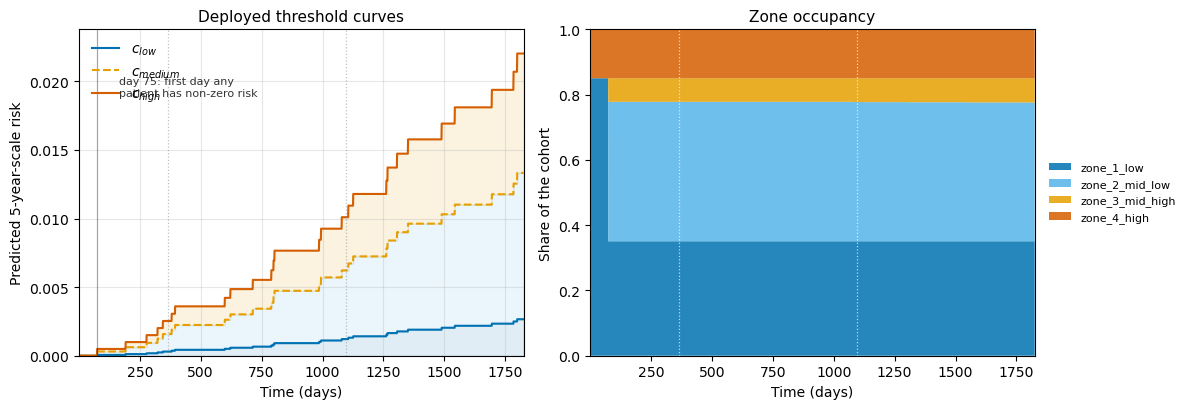

In [23]:
# ---- Visual check: the deployed curves, straight out of the bundle ----------
_tbl = loaded_bundle["thresholds_df"]
_t = _tbl["time"].to_numpy(dtype=float)
_lo = _tbl["t_low"].to_numpy(dtype=float)
_mid = _tbl["t_intermediate"].to_numpy(dtype=float)
_hi = _tbl["t_high"].to_numpy(dtype=float)
_horizons = np.asarray(loaded_bundle["report_time_points"], dtype=float)

# Okabe-Ito subset, same colours as the validation figures.
_c_low_col, _c_med_col, _c_high_col = "#0072B2", "#E69F00", "#D55E00"
_zone_cols = ["#0072B2", "#56B4E9", "#E69F00", "#D55E00"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
ax.fill_between(_t, 0, _lo, color=_zone_cols[0], alpha=0.12)
ax.fill_between(_t, _lo, _mid, color=_zone_cols[1], alpha=0.12)
ax.fill_between(_t, _mid, _hi, color=_zone_cols[2], alpha=0.12)
ax.plot(_t, _lo, color=_c_low_col, label="$c_{low}$")
ax.plot(_t, _mid, color=_c_med_col, linestyle="--", label="$c_{medium}$")
ax.plot(_t, _hi, color=_c_high_col, label="$c_{high}$")
for _h in _horizons:
    ax.axvline(_h, color="gray", linestyle=":", alpha=0.5, linewidth=0.9)
_first_day = loaded_bundle["threshold_config"].get("first_separating_day")
if _first_day is not None and np.isfinite(_first_day):
    ax.axvline(_first_day, color="black", linestyle="-", alpha=0.35, linewidth=0.9)
    ax.annotate(f"day {_first_day:.0f}: first day any\npatient has non-zero risk",
                xy=(_first_day, _hi.max() * 0.92), xytext=(_first_day + 90, _hi.max() * 0.86),
                fontsize=8, color="black", alpha=0.8)
ax.set_xlabel("Time (days)")
ax.set_ylabel("Predicted 5-year-scale risk")
ax.set_title("Deployed threshold curves", fontsize=11)
ax.set_ylim(0.0, _hi.max() * 1.08)
ax.set_xlim(_t.min(), _t.max())
ax.grid(alpha=0.3)
ax.legend(loc="upper left", frameon=False)

# Zone occupancy over the whole grid. Under the cohort rules the partition is
# time-invariant from the first separating day on, so these bands should be flat;
# a step in them means a boundary crossed a tie block somewhere.
ax = axes[1]
if "RISK" in globals():
    _zones = classify(RISK, {
        "c_low": _lo, "c_medium": _mid, "c_high": _hi,
        "high_cohort_cutoff": loaded_bundle["high_cohort_cutoff"],
        "high_reference_idx": int(np.argmin(np.abs(_t - loaded_bundle["high_reference_horizon"]))),
    })
    _shares = np.vstack([(_zones == z).mean(axis=0) for z in range(4)])
    ax.stackplot(_t, _shares, colors=_zone_cols, alpha=0.85,
                 labels=loaded_bundle["zone_labels"])
    ax.set_ylim(0.0, 1.0)
    ax.set_xlim(_t.min(), _t.max())
    ax.set_xlabel("Time (days)")
    ax.set_ylabel("Share of the cohort")
    ax.set_title("Zone occupancy", fontsize=11)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
    for _h in _horizons:
        ax.axvline(_h, color="white", linestyle=":", alpha=0.7, linewidth=0.9)
    print("zone shares at the reporting horizons:")
    for _h in _horizons:
        _j = int(np.argmin(np.abs(_t - _h)))
        print(f"  day {_h:>6.0f}  " + "  ".join(
            f"{lab.split('_', 2)[-1]}={_shares[z, _j]:.3f}"
            for z, lab in enumerate(loaded_bundle["zone_labels"])))
else:
    ax.text(0.5, 0.5, "run the derivation cell to draw zone occupancy",
            ha="center", va="center", transform=ax.transAxes, fontsize=9, color="gray")
    ax.set_axis_off()

plt.tight_layout()
plt.show()

In [24]:
# ---- Coefficient figures (unchanged) ---------------------------------------
# Same figures, same filenames, same output directory as before: the thesis
# references coef_diagnostic.png / coef_treatment.png at these paths.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Check if data exists
if 'coef_df' not in globals():
    raise NameError("coef_df not found. Run the bundle-load cell or coefficient-building cell first.")

# -------------------------
# Settings you can change
# -------------------------
use_nonzero_only = True
max_features_per_plot = 20  # Good limit for a PowerPoint slide
figsize = (10, 8)

# Dictionary to rename features in the chart. 
# Format: 'Original Name': 'New Custom Name'
feature_name_mapping = {
    'Oestrogen receptor status at CB_0.0': 'ER Status (Negative)',
    'Oestrogen receptor status at CB_1.0': 'ER Status (Positive)',
    'Isotype at CB_2.0': 'Isotype (Lobular)',
    'Isotype at CB_3.0': 'Isotype (Tubular)',
    'Isotype at CB_4.0': 'Isotype (Other)',
    'N (Regional nodes affected)_1.0': 'Regional nodes affected (1)',
    'Side location of the lesion': 'Side of the lesion (Right)',
    'Her2 overexpression (with immunohystochemistry) at CB_3.0': 'HER2 (Positive 3+)',
    'Her2 overexpression (with immunohystochemistry) at CB_2.0': 'HER2 (Dubious 2+)',
    'Her2 overexpression (with immunohystochemistry) at CB_1.0': 'HER2 (Negative 0/1+)',
    'Grade at CB_3.0': 'Grade (3)'
    # Add any other variables you want to rename here...
}

# Feature groups
treatment_features = [
    'Adjuvant therapy using biological drugs', 'Trastuzumab or other drugs',
    'Radiotherapy (RT) performed', 'Radiotherapy on chest wall',
    'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
    'Endocrine therapy performed', 'State (if hormone therapy prescribed)',
    'Treatment in association with chemotherapy', 'Chemotherapy performed',
    'Adjuvant chemotherapy', 'Conventional RT fraction',
    'Total administered dose', 'Boost dose administered', 'Neoadjuvant (bio) therapy only'
]

diagnostic_features = [
    'Age', 'Ki67 positive cells (%) at CB', 'Side location of the lesion',
    'Type of invasion at CB', 'Oestrogen receptor status at CB_0.0',
    'Oestrogen receptor status at CB_1.0', 'Her2 overexpression (with immunohystochemistry) at CB_1.0',
    'Her2 overexpression (with immunohystochemistry) at CB_2.0', 'Her2 overexpression (with immunohystochemistry) at CB_3.0',
    'Progesterone receptor status at CB_0.0', 'Progesterone receptor status at CB_1.0',
    'Grade at CB_2.0', 'Grade at CB_3.0', 'N (Regional nodes affected)_1.0',
    'N (Regional nodes affected)_23.0', 'Classification with respect to other lesions_2.0',
    'Classification with respect to other lesions_3.0', 'Disease extent_1.0',
    'Disease extent_2.0', 'Isotype at CB_2.0', 'Isotype at CB_3.0', 'Isotype at CB_4.0',
]

# ------------------------------------------------------------
# 1. Theme Colors & Settings (Dark Scheme for White Background)
# ------------------------------------------------------------
DARK_BLUE = '#004C99'   # Positive Coefficients (Increases Risk)
CRIMSON = '#E11D48'     # Negative Coefficients (Decreases Risk)
BLACK = '#000000'
MUTED_GRAY = '#E0E0E0'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': BLACK,
    'axes.labelcolor': BLACK,
    'xtick.color': BLACK,
    'ytick.color': BLACK,
})

# ------------------------------------------------------------
# 2. Plotting Function
# ------------------------------------------------------------
def _plot_feature_group_hq(base_df, feature_list, title, filename, legend_x_shift=1.0):
    group_df = base_df[base_df['feature'].isin(feature_list)].copy()

    if use_nonzero_only:
        group_df = group_df[group_df['coefficient'] != 0].copy()

    if group_df.empty:
        print(f"No coefficients found to plot for: {title}")
        return

    # Sort by absolute magnitude
    group_df['abs_coefficient'] = group_df['coefficient'].abs()
    
    if isinstance(max_features_per_plot, int) and max_features_per_plot > 0:
        group_df = group_df.sort_values('abs_coefficient', ascending=False).head(max_features_per_plot)

    # For barh, sort ascending so largest is at the top
    group_df = group_df.sort_values('abs_coefficient', ascending=True)

    # Clean up names for presentation: Check the dictionary first, otherwise use default cleaning
    group_df['clean_feature'] = group_df['feature'].apply(
        lambda x: feature_name_mapping.get(x, x.replace('_', ' ')[:50])
    )

    # Set colors based on sign
    colors = np.where(group_df['coefficient'] > 0, DARK_BLUE, CRIMSON)

    # Setup Figure
    fig, ax = plt.subplots(figsize=figsize, facecolor='white')
    ax.set_facecolor('white')

    # Draw bars
    bars = ax.barh(group_df['clean_feature'], group_df['coefficient'], color=colors, height=0.6, edgecolor='none')
    
    # Zero line
    ax.axvline(0, color=BLACK, linewidth=1.5, zorder=3)

    # Formatting
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20, loc='left', color=BLACK)
    ax.set_xlabel('Log Hazard Ratio (Coefficient)', fontsize=12, fontweight='bold', labelpad=12)
    ax.set_ylabel('') # Hide 'Feature' label

    # Clean spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False) # Hide Y axis line
    ax.spines['bottom'].set_linewidth(2)
    ax.spines['bottom'].set_color(BLACK)

    # Clean Ticks
    ax.tick_params(axis='y', length=0, labelsize=16, pad=10)
    ax.tick_params(axis='x', labelsize=16, width=1.5, length=5)

    # Grid
    ax.grid(axis='x', color=MUTED_GRAY, linestyle='-', linewidth=0.5, alpha=0.7)
    ax.set_axisbelow(True)

    # Add numeric labels to bars
    for bar in bars:
        width = bar.get_width()
        # Offset the text slightly past the end of the bar
        x_offset = 0.02 if width > 0 else -0.02
        ha = 'left' if width > 0 else 'right'
        color = DARK_BLUE if width > 0 else CRIMSON
        ax.text(width + x_offset, bar.get_y() + bar.get_height()/2, 
                f'{width:.2f}', va='center', ha=ha, fontsize=10, fontweight='bold', color=color)

    # Custom Legend
    legend_handles = [
        Patch(facecolor=DARK_BLUE, label='Increases Risk (> 0)'),
        Patch(facecolor=CRIMSON, label='Decreases Risk (< 0)'),
    ]
    ax.legend(
        handles=legend_handles,
        loc='lower right',
        bbox_to_anchor=(legend_x_shift, 0.02),
        frameon=False,
        fontsize=11,
    )

    # Dynamic X limits to fit labels and make the zero-line perfectly centered
    max_abs_val = group_df['abs_coefficient'].max()
    ax.set_xlim(-max_abs_val * 1.3, max_abs_val * 1.3)

    plt.tight_layout()
    plt.savefig(filename, dpi=300, transparent=True, bbox_inches='tight')
    plt.close()
    
    print(f"Saved: {filename}")

# ==============================================================================
# 3. Execution
# ==============================================================================
if CONFIG["save_coefficient_figures"]:
    plot_source_df = coef_df.copy()

    _plot_feature_group_hq(
        plot_source_df,
        diagnostic_features,
        'Diagnostic Features',
        'coef_diagnostic.png',
        legend_x_shift=1.0,
    )

    _plot_feature_group_hq(
        plot_source_df,
        treatment_features,
        'Treatment Features',
        'coef_treatment.png',
        legend_x_shift=0.5,
    )
else:
    print("CONFIG['save_coefficient_figures'] is False - figures not redrawn.")

Saved: coef_diagnostic.png
Saved: coef_treatment.png
